In [ ]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scienceplots

import USA
from models import Parameters, SEIR, SEIRD

plt.style.use([
    'science',
    #'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

RuntimeError: This version of jaxlib was built using AVX instructions, which your CPU and/or operating system do not support. You may be able work around this issue by building jaxlib from source.

In [16]:
# R0 = 12-18
# contagious period ~ 8 days
p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.9**(1/365), delta = 1/11, W=USA.get_od_matrix(), quarantine_factor=0.75)
solver = Tsit5()

y0 = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)

In [17]:
t0 = 0.0
t1 = 100.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

In [18]:
solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
print(solution.stats)

{'max_steps': 4096, 'num_accepted_steps': Array(100, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(100, dtype=int64, weak_type=True)}


In [19]:
ts = solution.ts
ys = solution.ys.reshape((-1, 4, p.n_cities)) # type: ignore

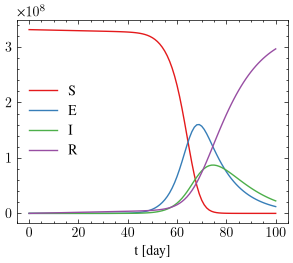

In [20]:
# plot S, E, I, R reduced over counties
plt.figure()
S_reduced = jnp.sum(ys[:, 0, :], axis=1)
E_reduced = jnp.sum(ys[:, 1, :], axis=1)
I_reduced = jnp.sum(ys[:, 2, :], axis=1)
R_reduced = jnp.sum(ys[:, 3, :], axis=1)
plt.plot(ts, S_reduced, label="S")
plt.plot(ts, E_reduced, label="E")
plt.plot(ts, I_reduced, label="I")
plt.plot(ts, R_reduced, label="R")
plt.xlabel("t [day]")
plt.legend()
plt.savefig("../figures/SEIR.pdf")

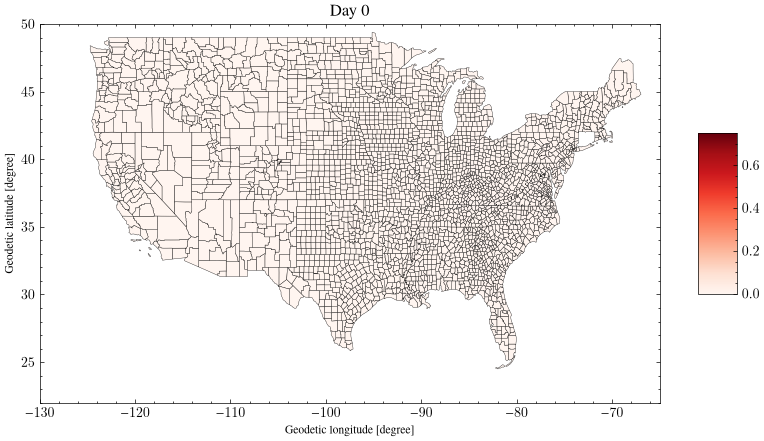

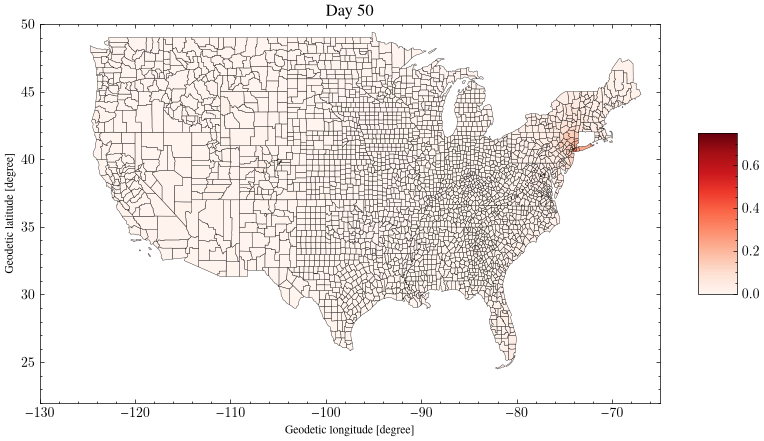

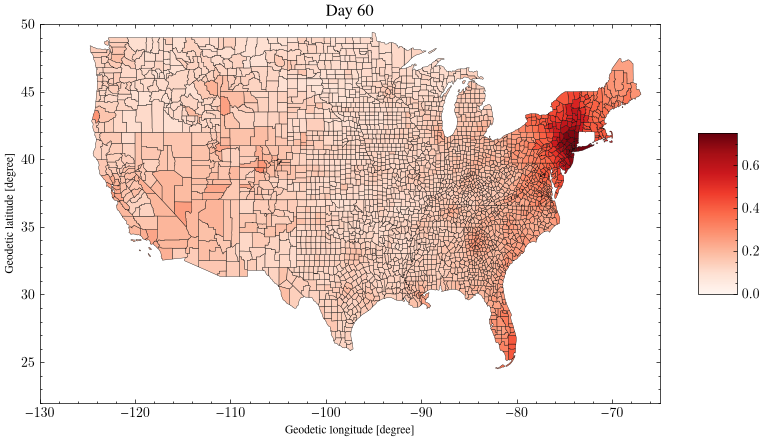

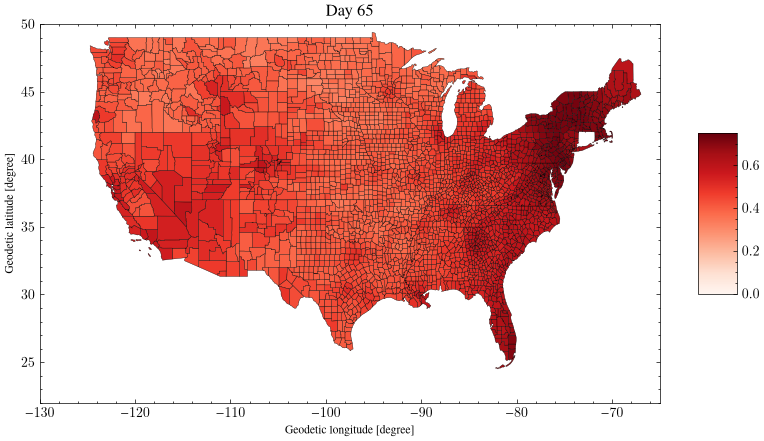

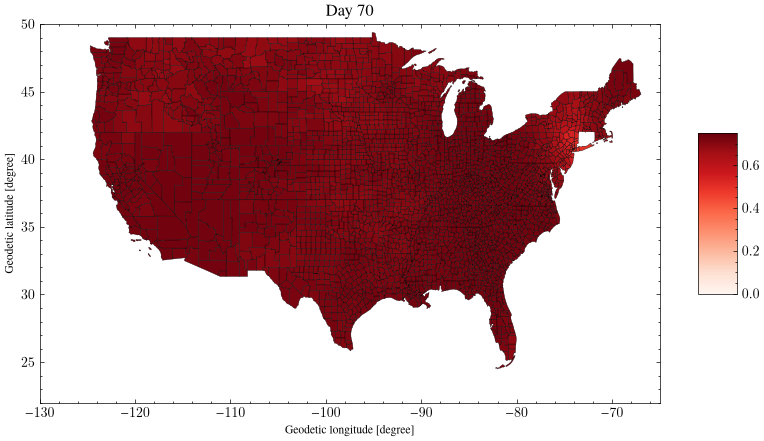

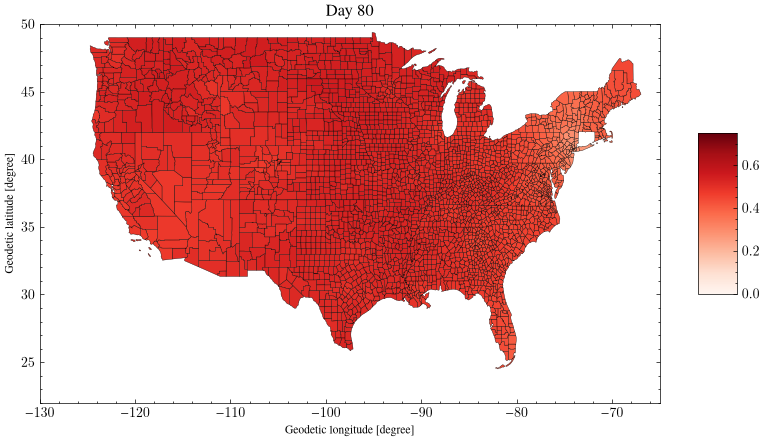

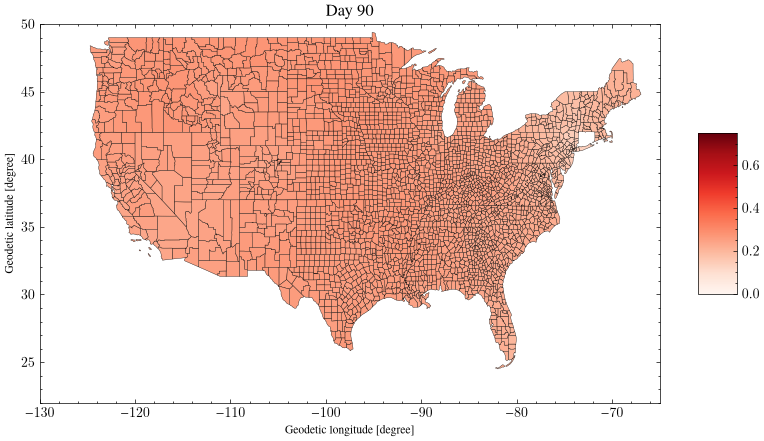

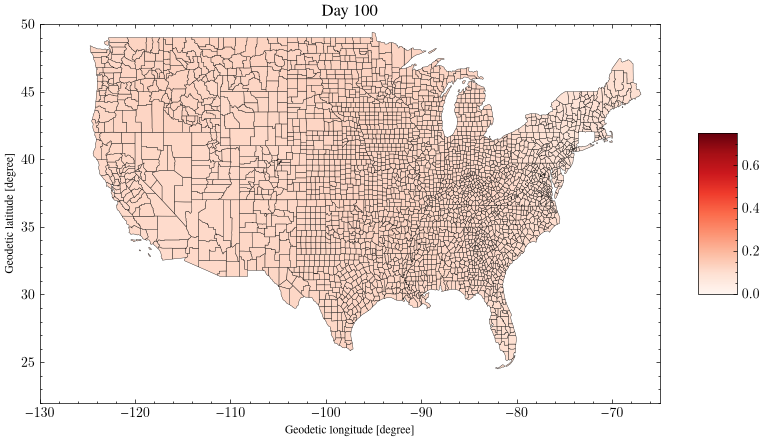

In [9]:
for day in [0, 50, 60, 65, 70, 80, 90, 100]:
    gdf = USA.get_gdf()
    plt.figure(figsize=(10,10))
    plt.title(f"Day {day}")
    S, E, I, R = ys[day, :, :]
    gdf['infected'] = (E + I) / (S + E + I + R)
    gdf.plot(column='infected', ax=plt.gca(), legend=True, cmap='Reds', edgecolor='black', linewidth=0.25, vmin=0, vmax=0.75)
    plt.xlim([-130, -65])
    plt.ylim([22, 50])
    plt.show()

In [ ]:
R0, CFR, VE = 15.0, 0.002, 0.97
ORIGIN, T = 36047, 300.0
ts = jnp.arange(0.0, T + 1.0, 1.0)
XLIM, YLIM = [-130, -65], [22, 50]

def simulate(quarantine=0.0, coverage=0.0):
    """Returns ys with shape (time, 5, county): S, E, I, R, D."""
    p = Parameters(alpha=1/8, beta=R0/8, gamma=0.0, delta=1/11, cfr=CFR,
                   W=USA.get_od_matrix(), quarantine_factor=quarantine)
    y0 = USA.make_initial_condition(initial_county=ORIGIN, initial_vaccination_rate=coverage * VE)
    y0 = jnp.concatenate([y0, jnp.zeros(p.n_cities)])
    sol = diffeqsolve(SEIRD, Tsit5(), t0=0.0, t1=T, dt0=1.0, y0=y0, args=p, saveat=SaveAt(ts=ts))
    return sol.ys.reshape((-1, 5, p.n_cities))

In [ ]:
ys = simulate()
tot = ys[0].sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, name in enumerate("SEIR"):
    ax[0].plot(ts, ys[:, k].sum(axis=1) / tot, label=name)
ax[0].set(xlabel="t [day]", ylabel="fraction of population", title="Compartments")
ax[0].legend()
ax[1].plot(ts, ys[:, 4].sum(axis=1), color="k")
ax[1].set(xlabel="t [day]", ylabel="cumulative deaths", title="Deaths")
plt.tight_layout()
plt.savefig("../figures/SEIRD_totals.pdf")

In [ ]:
gdf = USA.get_gdf()
S, E, I, R, D = (ys[:, k] for k in range(5))
active = np.clip((E + I) / (S + E + I + R), 1e-6, None)

days = [0, 20, 40, 60, 80, 100, 150, 200]
norm = LogNorm(vmin=1e-6, vmax=1)
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, day in zip(axes.flat, days):
    gdf["active"] = np.asarray(active[day])
    gdf.plot(column="active", ax=ax, cmap="Reds", norm=norm, edgecolor="none")
    ax.set(title=f"Day {day}", xlim=XLIM, ylim=YLIM)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(norm=norm, cmap="Reds")
fig.colorbar(sm, ax=axes, shrink=0.7, label="(E + I) / N")
plt.savefig("../figures/SEIRD_maps.pdf", bbox_inches="tight")

In [ ]:
threshold = 1e-4
above = np.asarray(active) > threshold
arrival = np.where(above.any(axis=0), np.asarray(ts)[above.argmax(axis=0)], np.nan)

gdf = USA.get_gdf()
gdf["arrival"] = arrival
fig, ax = plt.subplots(figsize=(8, 5))
gdf.plot(column="arrival", ax=ax, cmap="viridis_r", edgecolor="none", legend=True,
         legend_kwds={"label": f"day when (E+I)/N > {threshold:g}", "shrink": 0.7},
         missing_kwds={"color": "lightgrey"})
ax.set(xlim=XLIM, ylim=YLIM)
ax.set_axis_off()
plt.savefig("../figures/SEIRD_arrival.pdf", bbox_inches="tight")

In [ ]:
scenarios = {
    "no intervention":   dict(quarantine=0.0, coverage=0.0),
    "travel -50%":       dict(quarantine=0.5, coverage=0.0),
    "travel -90%":       dict(quarantine=0.9, coverage=0.0),
    "vaccinated 80%":    dict(quarantine=0.0, coverage=0.8),
    "vaccinated 92%":    dict(quarantine=0.0, coverage=0.92),
    "92% + travel -90%": dict(quarantine=0.9, coverage=0.92),
}
results = {name: simulate(**kw) for name, kw in scenarios.items()}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, r in results.items():
    ax[0].plot(ts, r[:, 2].sum(axis=1) / r[0].sum(), label=name)
ax[0].set(xlabel="t [day]", ylabel="infectious fraction", title="Infectious people")
ax[0].legend(fontsize=8)
ax[1].barh(list(results), [float(r[-1, 4].sum()) for r in results.values()], color="0.3")
ax[1].invert_yaxis()
ax[1].set(xlabel=f"deaths after {int(T)} days", title="Final death toll")
plt.tight_layout()
plt.savefig("../figures/SEIRD_scenarios.pdf")